# 04 – Default Model

**Goal:** Predict whether a loan will default, using only information known at origination.

**Setup:**
- 36-month mature loans (60-month loans issued in 2014-2015 had not matured)
- Time-based split: trained on loans issued 2007-2014, tested on loans issued in 2015
- Model A: borrower information only · Model B: borrower information + Lending Club grade
- Metric: AUC (ROC curve), because only about 15% of loans default

In [1]:
from pathlib import Path
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from dotenv import load_dotenv
from sqlalchemy import create_engine

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

load_dotenv("../.env")
engine = create_engine(os.getenv("DATABASE_URL"))

IMAGES_DIR = Path("../images")
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

MATURE_COLOR = "#1f5fbf"
ALL_COLOR = "#9a9a9a"
GAP_COLOR = "#e8743b"


def save_fig(fig, name):
    fig.savefig(IMAGES_DIR / f"{name}.png", bbox_inches="tight", dpi=150)

## 2. Data
36-month mature loans with origination information only. Outcome columns are not loaded (data leakage).

In [2]:
DATA_QUERY = """
SELECT
    l.id,
    d.year,
    l.grade,
    l.sub_grade,
    l.int_rate,
    l.loan_amnt,
    l.annual_inc,
    l.dti,
    l.fico_avg,
    l.revol_util,
    l.inq_last_6mths,
    l.open_acc,
    l.emp_length_years,
    l.home_ownership,
    l.verification_status,
    l.purpose,
    l.is_default
FROM loans_mature AS l
JOIN dim_date AS d ON l.issue_date = d.month_date
WHERE l.term_months = 36
"""

loans = pd.read_sql(DATA_QUERY, engine)
print(loans.shape)
print(f"Default rate: {loans['is_default'].mean():.2%}")

(621016, 17)
Default rate: 13.95%


## 3. Features
- `emp_length_missing`: 1 if employment length was not reported (20.86% vs 14.51% default in EDA)
- `loan_to_income`: loan amount / annual income (the same loan is heavier for a lower income)
- `log_annual_inc`: income is very skewed (up to $11M), so its logarithm is used

In [6]:
loans["emp_length_missing"] = loans["emp_length_years"].isna().astype(int)
loans["loan_to_income"] = (loans["loan_amnt"] / loans["annual_inc"]).clip(upper=1)
loans["log_annual_inc"] = np.log(loans["annual_inc"])

loans[["emp_length_missing", "loan_to_income", "log_annual_inc"]].describe().round(3)

,emp_length_missing,loan_to_income,log_annual_inc
count,621016.000,621016.000,621016.000
mean,0.058,0.196,11.029
std,0.234,0.106,0.549
min,0.000,0.000,7.090
25%,0.000,0.114,10.669
50%,0.000,0.180,11.002
75%,0.000,0.266,11.374
max,1.000,1.000,16.013


## 4. Time-based split
The model is trained on older loans and tested on newer loans, as it would be used in practice.
A random split would mix years and give an over-optimistic result.

In [7]:
train = loans[loans["year"] <= 2014]
test = loans[loans["year"] == 2015]

summary = pd.DataFrame({
    "loans": [len(train), len(test)],
    "default_rate_pct": [train["is_default"].mean() * 100, test["is_default"].mean() * 100],
}, index=["train (2007-2014)", "test (2015)"]).round(2)
summary

,loans,default_rate_pct
train (2007-2014),337992,13.16
test (2015),283024,14.89


In [8]:
print((loans["loan_to_income"] > 1).sum())

0


## 5. Models
Three logistic regression models are compared:
- **Grade only:** Lending Club's sub-grade (benchmark)
- **Model A:** borrower information only
- **Model B:** borrower information + sub-grade

In [9]:
NUMERIC_FEATURES = [
    "fico_avg", "log_annual_inc", "dti", "revol_util", "inq_last_6mths",
    "loan_amnt", "open_acc", "loan_to_income", "emp_length_missing",
]
CATEGORICAL_FEATURES = ["home_ownership", "verification_status", "purpose"]

MODEL_SPECS = {
    "Grade only": ([], ["sub_grade"]),
    "Model A": (NUMERIC_FEATURES, CATEGORICAL_FEATURES),
    "Model B": (NUMERIC_FEATURES, CATEGORICAL_FEATURES + ["sub_grade"]),
}


def build_model(numeric, categorical):
    """Logistic regression with imputation, scaling and one-hot encoding."""
    numeric_steps = Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
    ])
    preprocess = ColumnTransformer([
        ("num", numeric_steps, numeric),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical),
    ])
    return Pipeline([
        ("preprocess", preprocess),
        ("classifier", LogisticRegression(max_iter=1000)),
    ])


models, results = {}, []
for name, (numeric, categorical) in MODEL_SPECS.items():
    features = numeric + categorical
    model = build_model(numeric, categorical)
    model.fit(train[features], train["is_default"])

    train_auc = roc_auc_score(train["is_default"], model.predict_proba(train[features])[:, 1])
    test_auc = roc_auc_score(test["is_default"], model.predict_proba(test[features])[:, 1])

    models[name] = model
    results.append({"model": name, "train_auc": train_auc, "test_auc": test_auc})

results = pd.DataFrame(results).set_index("model").round(4)
results

,train_auc,test_auc
model,,
Grade only,0.6504,0.6786
Model A,0.6563,0.6548
Model B,0.6735,0.6876


### Results
| Model | Train AUC | Test AUC |
| --- | --- | --- |
| Grade only | 0.6504 | 0.6786 |
| Model A (borrower information) | 0.6563 | 0.6548 |
| Model B (A + sub-grade) | 0.6735 | 0.6876 |

- No overfitting: train and test AUC are close for all models.
- Lending Club's sub-grade alone (0.679) ranks risk better than our borrower variables (0.655),
  because Lending Club uses the full credit report.
- Combining both gives the best result (0.688): our variables add some information the grade does not capture.
- Test AUC can be higher than train AUC because the 2015 borrowers differ more in risk, which makes ranking easier.

## 6. Evaluation
- **ROC curve:** how well each model separates defaults from good loans on the test set (2015).
- **Coefficients:** which borrower variables raise or lower default risk in the borrower data model.

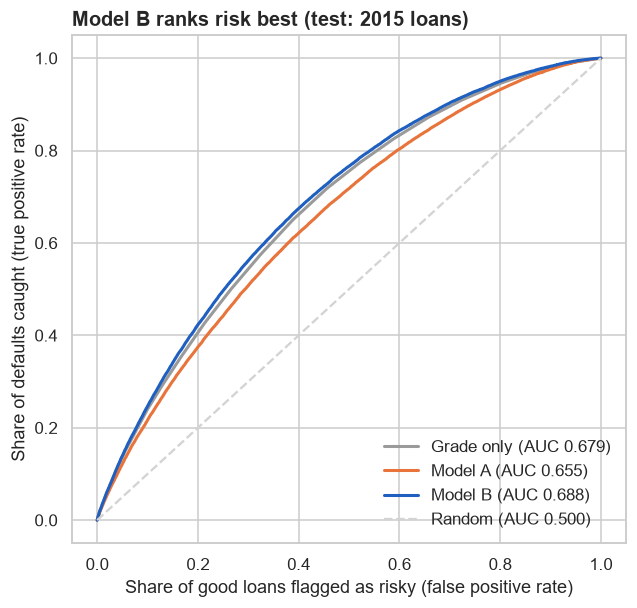

In [11]:
MODEL_COLORS = {"Grade only": ALL_COLOR, "Model A": GAP_COLOR, "Model B": MATURE_COLOR}

test_scores = {}
fig, ax = plt.subplots(figsize=(6.5, 6))

for name, model in models.items():
    numeric, categorical = MODEL_SPECS[name]
    scores = model.predict_proba(test[numeric + categorical])[:, 1]
    test_scores[name] = scores

    false_positive_rate, true_positive_rate, _ = roc_curve(test["is_default"], scores)
    auc = roc_auc_score(test["is_default"], scores)
    ax.plot(false_positive_rate, true_positive_rate, color=MODEL_COLORS[name], lw=2,
            label=f"{name} (AUC {auc:.3f})")

ax.plot([0, 1], [0, 1], color="lightgrey", linestyle="--", label="Random (AUC 0.500)")
ax.set_xlabel("Share of good loans flagged as risky (false positive rate)")
ax.set_ylabel("Share of defaults caught (true positive rate)")
ax.set_title("Model B ranks risk best (test: 2015 loans)", loc="left", fontsize=13, fontweight="bold")
ax.legend(loc="lower right", frameon=False)

save_fig(fig, "07_roc_curve")
plt.show()

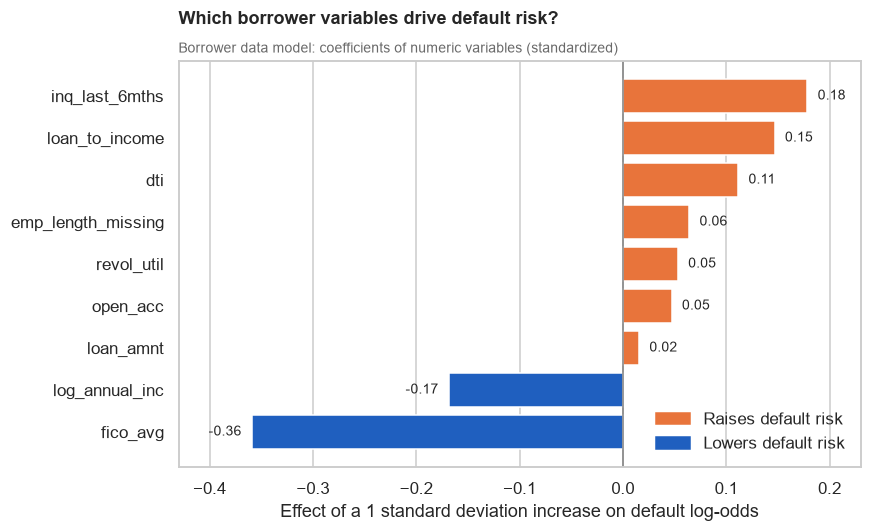

In [14]:
from matplotlib.patches import Patch

model_a = models["Model A"]
feature_names = model_a.named_steps["preprocess"].get_feature_names_out()
coefficients = pd.Series(model_a.named_steps["classifier"].coef_[0], index=feature_names)

numeric_coefficients = (
    coefficients[coefficients.index.str.startswith("num__")]
    .rename(lambda name: name.replace("num__", ""))
    .sort_values()
)

colors = [GAP_COLOR if value > 0 else MATURE_COLOR for value in numeric_coefficients]

fig, ax = plt.subplots(figsize=(8, 4.8))
ax.barh(numeric_coefficients.index, numeric_coefficients.values, color=colors)
ax.axvline(0, color="grey", lw=1)

for i, value in enumerate(numeric_coefficients.values):
    ax.text(
        value + (0.01 if value > 0 else -0.01), i, f"{value:.2f}",
        va="center", ha="left" if value > 0 else "right", fontsize=9,
    )

legend_items = [
    Patch(color=GAP_COLOR, label="Raises default risk"),
    Patch(color=MATURE_COLOR, label="Lowers default risk"),
]
ax.legend(handles=legend_items, loc="lower right", frameon=False)

ax.set_title(
    "Which borrower variables drive default risk?",
    loc="left", fontsize=12, fontweight="bold", pad=24,
)
ax.text(
    0, 1.02, "Borrower data model: coefficients of numeric variables (standardized)",
    transform=ax.transAxes, fontsize=9, color="dimgrey",
)
ax.set_xlabel("Effect of a 1 standard deviation increase on default log-odds")
ax.set_xlim(-0.43, 0.23)
ax.grid(axis="y", visible=False)

save_fig(fig, "08_model_a_coefficients")
plt.show()

### What drives default risk (borrower data model)
- FICO is the strongest factor (-0.36), followed by income (-0.17): higher values lower the risk.
- Recent credit inquiries (0.18) and loan-to-income (0.15) raise the risk the most.
  Loan amount alone barely matters (0.02): what matters is the loan size relative to income.
- Coefficients show the effect of each variable **with the others held constant**. Revolving utilization was
  strong in the EDA but weak here, because it overlaps with FICO (correlation -0.37).

## 7. Risk bands
Model B's test predictions are split into 10 equal groups (deciles) to check two things:
- **Ranking:** does the actual default rate rise steadily from the lowest to the highest predicted risk?
- **Calibration:** when the model predicts 20% risk, do about 20% of those loans actually default?

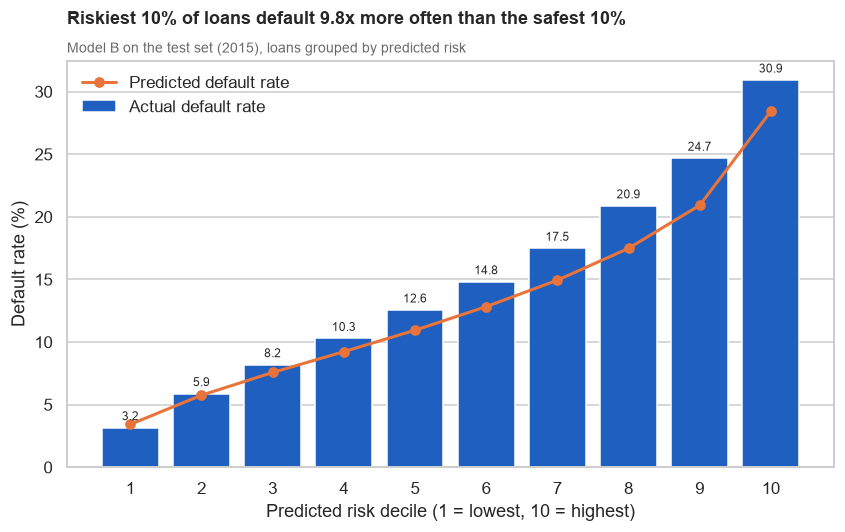

,loans,predicted_pct,actual_pct
decile,,,
1,28303,3.43,3.16
2,28302,5.75,5.88
3,28302,7.57,8.19
4,28303,9.23,10.29
5,28302,10.94,12.56
6,28302,12.83,14.81
7,28303,14.94,17.49
8,28302,17.49,20.88
9,28302,20.92,24.68


In [15]:
FEATURES_B = NUMERIC_FEATURES + CATEGORICAL_FEATURES + ["sub_grade"]
scores_b = test_scores["Model B"]

decile_table = (
    pd.DataFrame({
        "decile": pd.qcut(scores_b, 10, labels=range(1, 11)),
        "predicted": scores_b,
        "actual": test["is_default"].values,
    })
    .groupby("decile", observed=True)
    .agg(loans=("actual", "size"), predicted_pct=("predicted", "mean"), actual_pct=("actual", "mean"))
)
decile_table[["predicted_pct", "actual_pct"]] *= 100

fig, ax = plt.subplots(figsize=(9, 4.8))
ax.bar(decile_table.index, decile_table["actual_pct"], color=MATURE_COLOR, label="Actual default rate")
ax.plot(decile_table.index, decile_table["predicted_pct"], color=GAP_COLOR, marker="o", lw=2,
        label="Predicted default rate")

for decile, value in decile_table["actual_pct"].items():
    ax.text(decile, value + 0.6, f"{value:.1f}", ha="center", fontsize=8)

ratio = decile_table["actual_pct"].iloc[-1] / decile_table["actual_pct"].iloc[0]
ax.set_title(
    f"Riskiest 10% of loans default {ratio:.1f}x more often than the safest 10%",
    loc="left", fontsize=12, fontweight="bold", pad=24,
)
ax.text(
    0, 1.02, "Model B on the test set (2015), loans grouped by predicted risk",
    transform=ax.transAxes, fontsize=9, color="dimgrey",
)
ax.set_xlabel("Predicted risk decile (1 = lowest, 10 = highest)")
ax.set_ylabel("Default rate (%)")
ax.set_xticks(decile_table.index)
ax.legend(loc="upper left", frameon=False)
ax.grid(axis="x", visible=False)

save_fig(fig, "09_risk_deciles")
plt.show()

decile_table.round(2)

### Ranking and calibration
- **Ranking:** the actual default rate rises at every decile, from 3.16% to 30.93%: the riskiest 10% of loans
  default 9.8x more often than the safest 10%.
- **Calibration:** predictions are accurate for low-risk loans but too low for risky loans
  (decile 9: 20.92% predicted vs 24.68% actual). The model was trained on 2007-2014, when default rates were lower;
  the 2015 deterioration was concentrated in riskier borrowers (see Q9b).
- The model can be used to **rank** applicants, but its probabilities should be recalibrated on recent data
  before being used for loss forecasting or pricing.

In [16]:
BAND_LABELS = ["Very low", "Low", "Medium", "High", "Very high"]

train_scores_b = models["Model B"].predict_proba(train[FEATURES_B])[:, 1]
band_thresholds = np.quantile(train_scores_b, [0.30, 0.60, 0.80, 0.90])
band_edges = [0, *band_thresholds, 1]


def assign_band(scores):
    """Risk band from predicted default probability, using thresholds fixed on training data."""
    return pd.cut(scores, bins=band_edges, labels=BAND_LABELS, include_lowest=True)


print("Band thresholds (default probability):", np.round(band_thresholds, 4))

band_table = (
    pd.DataFrame({
        "band": assign_band(scores_b),
        "predicted": scores_b,
        "actual": test["is_default"].values,
    })
    .groupby("band", observed=True)
    .agg(loans=("actual", "size"), predicted_pct=("predicted", "mean"), actual_pct=("actual", "mean"))
)
band_table["loan_share_pct"] = band_table["loans"] / band_table["loans"].sum() * 100
band_table[["predicted_pct", "actual_pct"]] *= 100
band_table.round(2)

Band thresholds (default probability): [0.0856 0.1386 0.1888 0.2295]


,loans,predicted_pct,actual_pct,loan_share_pct
band,,,,
Very low,87536,5.67,5.84,30.93
Low,82500,11.09,12.68,29.15
Medium,55455,16.18,19.12,19.59
High,27668,20.73,24.53,9.78
Very high,29865,28.16,30.72,10.55


### Risk bands
Band thresholds are fixed on the training predictions (30% / 30% / 20% / 10% / 10%) and applied to the test set.

| Band | Share of test loans | Predicted default | Actual default |
| --- | --- | --- | --- |
| Very low | 30.93% | 5.67% | 5.84% |
| Low | 29.15% | 11.09% | 12.68% |
| Medium | 19.59% | 16.18% | 19.12% |
| High | 9.78% | 20.73% | 24.53% |
| Very high | 10.55% | 28.16% | 30.72% |

- Actual default rises steadily from Very low to Very high (5.3x), so the bands separate risk well.
- The share of loans in each band barely changed in 2015, but actual default rates were higher in every band:
  2015 borrowers did not look riskier on the model's variables, yet they defaulted more often.
  This matches Q9b, where FICO stayed flat while default rose in 2014-2015.